(35000,) (35000,)
(7000,) (7000,)
N_CLASSES: 7
(47, 34, 3)
max_H: 60 || max_W: 60
min_H: 20 || min_W: 20


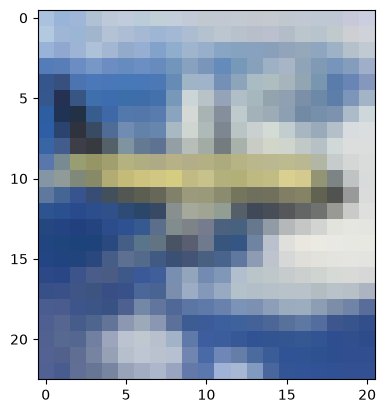

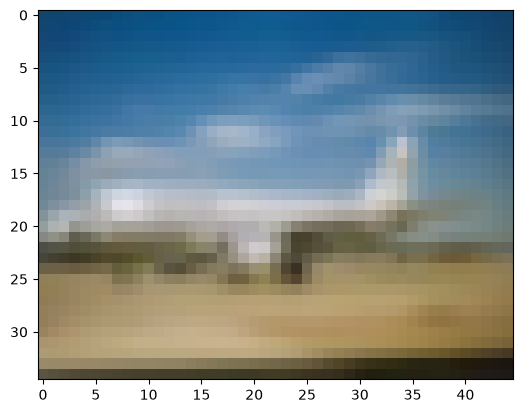

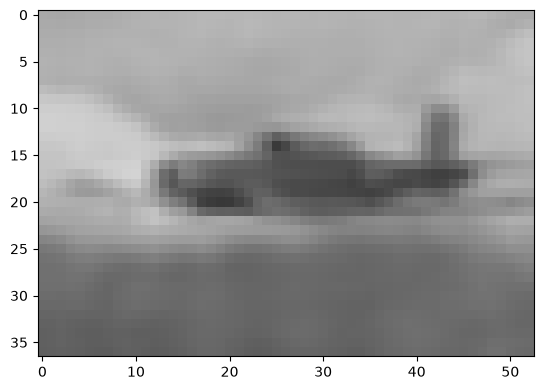

In [69]:
import numpy as np
import matplotlib.pyplot as plt
import random
import torch
import torch.nn as nn
from torchvision import datasets, transforms
from torchsummary import summary
from torch.utils.data import DataLoader, Dataset
from tqdm import tqdm
import torchvision
from PIL import Image

train_data = np.load('Numarul2-train/2_2_train.npz', allow_pickle=True)
x_train, y_train = train_data['x'], train_data['y']
print(x_train.shape, y_train.shape)

test_data = np.load('Numarul2-test/2_2_test.npz', allow_pickle=True)
x_test, y_test = test_data['x'], test_data['y']
print(x_test.shape, y_test.shape)

N_CLASSES = len(np.unique(y_train))
print(f"N_CLASSES: {N_CLASSES}")

print(x_train[0].shape)
dim_H = set()
dim_W = set()
for img in x_train:
    dim_H.add(img.shape[0])
    dim_W.add(img.shape[1])

print(f"max_H: {max(dim_H)} || max_W: {max(dim_W)}")
print(f"min_H: {min(dim_H)} || min_W: {min(dim_W)}")

H = W = 32

IMAGES_TO_SHOW = 3
for i in range(IMAGES_TO_SHOW):
    random_idx = np.random.randint(low=0, high=(len(x_train)-1))
    img = x_train[random_idx]
    plt.figure(), plt.imshow(img)



In [70]:
class CustomDataset(Dataset):
    def __init__(self, x, y):
        self.images = x
        self.labels = y

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        image = Image.fromarray(self.images[idx])
        label = self.labels[idx]

        image = image.resize(size=(H, W))

        image = torch.as_tensor(np.array(image), dtype=torch.float32)
        image = image / 255.0
        image = torch.permute(image, (2, 0, 1))

        label = torch.as_tensor(label, dtype=torch.int64)
        
        return image, label


train_dataset = CustomDataset(x_train, y_train)
test_dataset = CustomDataset(x_test, y_test)

train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=64, shuffle=False)


In [71]:
class Model(nn.Module):
    def __init__(self, in_channels=3, n_classes=N_CLASSES, act=nn.functional.relu):
        super().__init__()
        self.act = act

        # in -> (3, 32, 32)
        self.conv1 = nn.Conv2d(in_channels=in_channels, out_channels=32, kernel_size=3, padding=1) # -> (32, 32, 32)
        self.pool1 = nn.MaxPool2d(kernel_size=2) # -> (32, 16, 16)
        self.conv2 = nn.Conv2d(in_channels=32, out_channels=32, kernel_size=3, padding=1) # -> (32, 16, 16)
        self.pool2 = nn.MaxPool2d(kernel_size=2) # -> (32, 8, 8)
        self.conv3 = nn.Conv2d(in_channels=32, out_channels=16, kernel_size=3, padding=1) # -> (16, 8, 8)
        self.pool3 = nn.MaxPool2d(kernel_size=2) # -> (16, 4, 4)


        self.fc1 = nn.Linear(16 * 4 * 4, 256)                               # 256 -> 256
        self.fc2 = nn.Linear(256, n_classes)

    def forward(self, x):
        x = self.pool1(self.act(self.conv1(x)))
        x = self.pool2(self.act(self.conv2(x)))
        x = self.pool3(self.act(self.conv3(x)))
        
        x = x.flatten(1)
        x = self.act(self.fc1(x))
        x = self.fc2(x)

        return x


device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = Model().to(device)
optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3)
loss_fn = nn.CrossEntropyLoss()
epochs = 10


In [72]:
def train(model, loader, optimizer, loss_fn, device):
    model.train()
    total_loss, correct, total = 0.0, 0, 0
    for x, y in loader:
        x, y = x.to(device), y.to(device)
        optimizer.zero_grad()
        out = model(x)
        loss = loss_fn(out, y)
        loss.backward()
        optimizer.step()
        total_loss += loss.item()
        correct += (out.argmax(-1) == y).sum().item()
        total += y.size(0)
    return total_loss / len(loader), correct / total


def test(model, loader, loss_fn, device):
    model.eval()
    total_loss, correct, total = 0.0, 0, 0
    with torch.no_grad():
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            out = model(x)
            loss = loss_fn(out, y)
            total_loss += loss.item()
            correct += (out.argmax(-1) == y).sum().item()
            total += y.size(0)
        return total_loss / len(loader), correct / total


best = 0
for epoch in range(epochs):
    train_loss, train_acc = train(model, train_loader, optimizer, loss_fn, device)
    test_loss, test_acc = test(model, test_loader, loss_fn, device)
    print(f"train_loss: {train_loss:.4f} || train_acc: {train_acc:.4f} || test_loss: {test_loss:.4f} || test_acc: {test_acc:.4f}")
    if test_acc > best:
        best = test_acc
        torch.save(model, 'model.pt')


def evaluate(model, loader, device):
    model.eval()
    correct, total = 0, 0
    with torch.no_grad():
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            out = model(x)
            correct += (out.argmax(-1) == y).sum().item()
            total += y.size(0)
        return correct / total


model = torch.load('model.pt', weights_only=False)
test_acc = evaluate(model, test_loader, device)
print(f'{test_acc:.4f}')


train_loss: 1.3148 || train_acc: 0.4876 || test_loss: 1.0866 || test_acc: 0.5807
train_loss: 1.0290 || train_acc: 0.6107 || test_loss: 0.9407 || test_acc: 0.6514
train_loss: 0.8969 || train_acc: 0.6660 || test_loss: 0.8108 || test_acc: 0.6973
train_loss: 0.7944 || train_acc: 0.7053 || test_loss: 0.7357 || test_acc: 0.7290
train_loss: 0.7203 || train_acc: 0.7359 || test_loss: 0.7210 || test_acc: 0.7407
train_loss: 0.6595 || train_acc: 0.7604 || test_loss: 0.6633 || test_acc: 0.7597
train_loss: 0.6117 || train_acc: 0.7775 || test_loss: 0.6251 || test_acc: 0.7679
train_loss: 0.5744 || train_acc: 0.7922 || test_loss: 0.6135 || test_acc: 0.7796
train_loss: 0.5409 || train_acc: 0.8033 || test_loss: 0.6528 || test_acc: 0.7700
train_loss: 0.5111 || train_acc: 0.8156 || test_loss: 0.6049 || test_acc: 0.7844
0.7844
